# 42 · Project: a PID drone racer (Skydio X2, MuJoCo Menagerie)
A quadrotor has 4 motors and 6 degrees of freedom: it can't move sideways without tilting. That makes it the classic
**cascaded** control problem, the same structure that runs inside every PX4/Betaflight flight controller:

```
position error ──PID──▶ desired acceleration ──▶ desired tilt + thrust ──PD──▶ body torques ──mixer──▶ 4 motor thrusts
     (outer loop, slow)                                      (inner loop, fast)
```
We build it bottom-up and measure every layer: the motor mixer, a step response, why the integral term exists
(an unknown payload), what feed-forward buys on a race course, and what a wind gust does. Then we race.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from vlacourse import show_video
from vlacourse import showcase as sc
from vlacourse.drone import DroneRace, CascadedController, PID, catmull_rom, PathFollower, gate_passed, Film

dr = DroneRace()
print(f"Skydio X2: mass {dr.mass:.3f} kg, 4 motors at (x, y) = {dr.motor_xy.round(2).tolist()}, max 13 N each")

Skydio X2: mass 1.325 kg, 4 motors at (x, y) = [[-0.14, -0.18], [-0.14, 0.18], [0.14, 0.18], [0.14, -0.18]], max 13 N each


## 1. The mixer: what the 4 motors can do
Each motor pushes up with force $f_i$ at position $(x_i, y_i)$ and twists the body about $z$ with $k_i f_i$
(propellers spin in alternating directions). Total thrust and torques are linear in the motor forces:
$$\begin{bmatrix}T\\ \tau_x\\ \tau_y\\ \tau_z\end{bmatrix} = \underbrace{\begin{bmatrix}1&1&1&1\\ y_1&y_2&y_3&y_4\\ -x_1&-x_2&-x_3&-x_4\\ k_1&k_2&k_3&k_4\end{bmatrix}}_{A}\begin{bmatrix}f_1\\f_2\\f_3\\f_4\end{bmatrix}$$
so the controller asks for $(T, \tau)$ and the mixer solves $f = A^{-1}(T, \tau)$.

In [2]:
print("hover:           ", dr.mixer(dr.mass * 9.81, np.zeros(3)).round(2), "N  (= m g / 4 each)")
print("roll right a bit:", dr.mixer(dr.mass * 9.81, np.array([0.2, 0, 0])).round(2), "N  (+y motors push harder)")
print("yaw:             ", dr.mixer(dr.mass * 9.81, np.array([0, 0, 0.05])).round(2), "N  (one diagonal pair faster)")

hover:            [3.25 3.25 3.25 3.25] N  (= m g / 4 each)
roll right a bit: [2.97 3.53 3.53 2.97] N  (+y motors push harder)
yaw:              [2.63 3.87 2.63 3.87] N  (one diagonal pair faster)


## 2. A step response, and what each gain does
Command the drone 1 m forward. It has to pitch first (inner loop), then accelerate, then pitch back to stop.

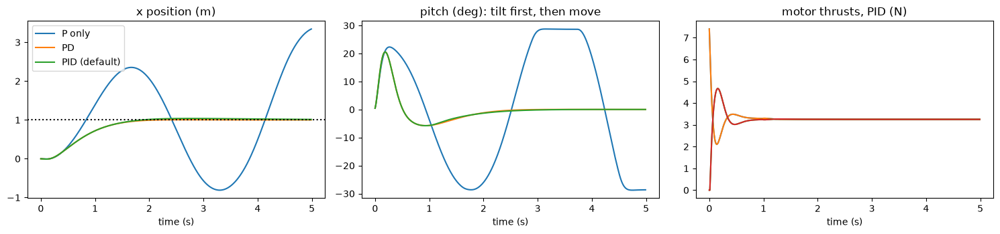

PID: overshoot 3.8%, within 5 cm after 1.58 s


In [3]:
def fly(target, T=5.0, payload=0.0, wind=None, **kw):
    d = DroneRace(payload=payload); s = d.reset(pos=(0, 0, 1.0)); c = CascadedController(d, **kw); c.reset(); log = []
    for k in range(int(T / d.dt)):
        f, info = c(s, np.asarray(target, float)); s = d.step(f, wind=None if wind is None else wind(k * d.dt))
        log.append(np.r_[k * d.dt, s["pos"], s["rpy"], f])
    return np.array(log)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for label, kw in [("P only", dict(pos_gains=(4.0, 0, 0))), ("PD", dict(pos_gains=(4.0, 0, 3.2))), ("PID (default)", {})]:
    L = fly([1, 0, 1], **kw)
    ax[0].plot(L[:, 0], L[:, 1], label=label); ax[1].plot(L[:, 0], np.degrees(L[:, 5]), label=label)
L = fly([1, 0, 1]); ax[2].plot(L[:, 0], L[:, 7:11]); ax[2].set_title("motor thrusts, PID (N)")
ax[0].axhline(1, c="k", ls=":"); ax[0].set_title("x position (m)"); ax[0].legend(); ax[1].set_title("pitch (deg): tilt first, then move")
for a in ax: a.set_xlabel("time (s)")
plt.tight_layout(); plt.show()
x = fly([1, 0, 1])[:, 1]
print(f"PID: overshoot {100 * (x.max() - 1):.1f}%, within 5 cm after {np.argmax(np.abs(x - 1) < 0.05) * dr.dt:.2f} s")

P alone oscillates: nothing damps the motion (the drone is a double integrator). D supplies the damping.

## 3. Why the integral term exists: an unknown payload
Strap a 0.3 kg box under the drone (23% more mass) without telling the controller. Its gravity feed-forward is
now too small, and only the integral term can find the missing thrust.

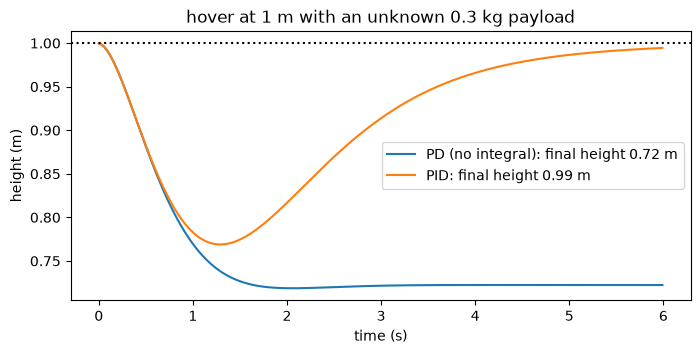

In [4]:
plt.figure(figsize=(8, 3.5))
for ui in [False, True]:
    L = fly([0, 0, 1], T=6, payload=0.3, use_integral=ui)
    plt.plot(L[:, 0], L[:, 3], label=f"{'PID' if ui else 'PD (no integral)'}: final height {L[-1, 3]:.2f} m")
plt.axhline(1, c="k", ls=":"); plt.ylabel("height (m)"); plt.xlabel("time (s)"); plt.title("hover at 1 m with an unknown 0.3 kg payload"); plt.legend(); plt.show()

## 4. A wind gust
A 2 N sideways push for 4 seconds (about 15% of the drone's weight).

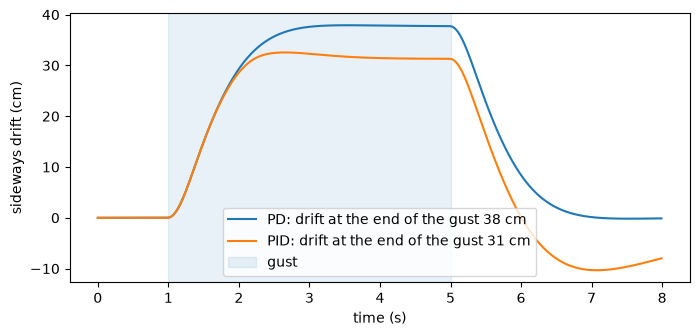

In [5]:
gust = lambda t: np.array([0, 2.0, 0]) if 1 <= t < 5 else np.zeros(3)
plt.figure(figsize=(8, 3.5))
for ui in [False, True]:
    L = fly([0, 0, 1], T=8, wind=gust, use_integral=ui)
    plt.plot(L[:, 0], 100 * L[:, 2], label=f"{'PID' if ui else 'PD'}: drift at the end of the gust {100 * L[499, 2]:.0f} cm")
plt.axvspan(1, 5, color="tab:blue", alpha=0.1, label="gust"); plt.ylabel("sideways drift (cm)"); plt.xlabel("time (s)"); plt.legend(); plt.show()

The integral term helps, but slowly: it has to *accumulate* the error first. For fast disturbances you need
bandwidth (higher gains, a faster inner loop) or a disturbance observer. Exercise: double the position gains and
repeat. When does the drone start to oscillate?

## 5. The race
Five gates at different heights and headings. A smooth path (Catmull-Rom spline) runs through the gate centres; a
"carrot" moves along it at a fixed speed, and the controller chases the carrot.
**Feed-forward:** tell the controller the carrot's velocity and acceleration, not only its position. Then the PID
only has to correct *errors*, instead of being the whole reason the drone moves.

In [6]:
GATES = [(2.5, 0.0, 1.2, 0.0), (5.0, 2.0, 1.6, np.pi / 2), (3.0, 4.0, 1.0, np.pi), (0.0, 3.5, 1.8, np.pi), (-1.5, 1.5, 1.2, -np.pi / 2)]
SIZE = 0.9
WPS = [np.array([0, 0, 1.0])] + [np.array(g[:3]) for g in GATES] + [np.array([0, 0, 1.0])]
PTS, SEG = catmull_rom(WPS)
print(f"course length {SEG[-1]:.1f} m")

def race(speed, feedforward=True, film=None, wind=None):
    d = DroneRace(gates=GATES, gate_size=SIZE); s = d.reset(pos=(0, 0, 1.0)); c = CascadedController(d); c.reset()
    fol = PathFollower(PTS, SEG, speed); passed, prev, err, path = [], s["pos"].copy(), [], []
    fm = Film(d) if film else None; frames = []
    for k in range(int((SEG[-1] / speed + 2.5) / d.dt)):
        tgt, v, a, _ = fol(k * d.dt)
        f, _ = c(s, tgt, v if feedforward else np.zeros(3), a if feedforward else np.zeros(3))
        s = d.step(f, wind=None if wind is None else wind(k * d.dt))
        passed += [g for g, gt in enumerate(GATES) if g not in passed and gate_passed(prev, s["pos"], gt, SIZE)]
        prev = s["pos"].copy(); err.append(np.linalg.norm(s["pos"] - tgt)); path.append(s["pos"].copy())
        if fm is not None and k % 2 == 0:                                   # 50 fps video from a 100 Hz simulation
            frames.append(film(fm.frame(passed), s, speed, passed))
    return dict(gates=len(passed), err=np.array(err), path=np.array(path), frames=frames, lap=SEG[-1] / speed)

rows = []
for speed in [2.0, 3.0, 4.0]:
    for ff in [False, True]:
        r = race(speed, ff); rows.append((speed, ff, r))
        print(f"speed {speed:.0f} m/s, feed-forward {'on ' if ff else 'off'}: gates {r['gates']}/5, tracking error mean {100 * r['err'].mean():4.0f} cm, max {100 * r['err'].max():4.0f} cm")

course length 16.9 m
speed 2 m/s, feed-forward off: gates 5/5, tracking error mean  118 cm, max  158 cm
speed 2 m/s, feed-forward on : gates 5/5, tracking error mean   14 cm, max   57 cm
speed 3 m/s, feed-forward off: gates 3/5, tracking error mean  151 cm, max  233 cm
speed 3 m/s, feed-forward on : gates 5/5, tracking error mean   47 cm, max  128 cm
speed 4 m/s, feed-forward off: gates 3/5, tracking error mean  174 cm, max  296 cm
speed 4 m/s, feed-forward on : gates 0/5, tracking error mean  136 cm, max  343 cm


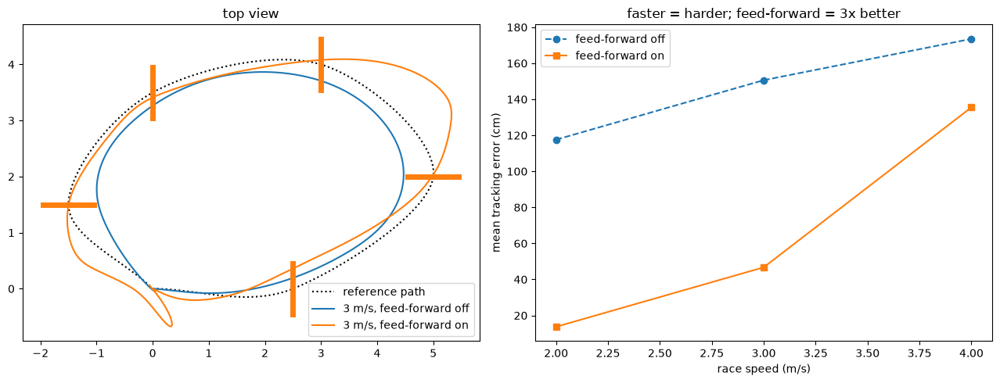

In [7]:
fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(1, 2, 1)
ax.plot(PTS[:, 0], PTS[:, 1], "k:", label="reference path")
for speed, ff, r in rows:
    if speed == 3.0:
        ax.plot(r["path"][:, 0], r["path"][:, 1], label=f"3 m/s, feed-forward {'on' if ff else 'off'}")
for x, y, z, yaw in GATES:
    ax.plot([x - 0.45 * np.sin(yaw), x + 0.45 * np.sin(yaw)], [y + 0.45 * np.cos(yaw), y - 0.45 * np.cos(yaw)], c="tab:orange", lw=5)
ax.axis("equal"); ax.legend(); ax.set_title("top view")
ax = fig.add_subplot(1, 2, 2)
for ff, m in [(False, "o--"), (True, "s-")]:
    sp = [r[0] for r in rows if r[1] == ff]; e = [100 * r[2]["err"].mean() for r in rows if r[1] == ff]
    ax.plot(sp, e, m, label=f"feed-forward {'on' if ff else 'off'}")
ax.set_xlabel("race speed (m/s)"); ax.set_ylabel("mean tracking error (cm)"); ax.legend(); ax.set_title("faster = harder; feed-forward = 3x better")
plt.tight_layout(); plt.show()

At 4 m/s the drone can no longer follow the turns: the controller saturates at its 0.5 rad (29°) tilt limit, the
error grows past the gate size, and gates are missed. Exercise: raise `max_tilt`. How fast can you go now, and
what fails next?

## 6. Share-ready video
A 1280×720 chase camera with the flight trail; gates turn green as they are passed.

In [8]:
def overlay(img, s, speed, passed):
    img = sc.caption(img, f"PID drone racer · Skydio X2 · {speed:.1f} m/s target", where="top", size=26)
    img = sc.badge(img, f"gates {len(passed)}/5", corner="tr", size=24)
    return sc.caption(img, f"cascaded PID + feed-forward · tilt {np.degrees(np.hypot(*s['rpy'][:2])):.0f}°  ·  height {s['pos'][2]:.1f} m", size=20)

best = 3.0
r = race(best, True, film=overlay)
intro = sc.title_card("PID drone racer", "cascaded PID control of a quadrotor\nMuJoCo · Skydio X2 (Menagerie)", size=(720, 1280), n=75)
video = intro + r["frames"] + [sc.badge(r["frames"][-1], f"lap {r['lap']:.1f} s · {r['gates']}/5 gates", corner="bl", size=30)] * 60
show_video(video, fps=50, title="42 drone PID racer HD", width=960)
sc.export(video, "outputs/42_drone_pid_racer.mp4", fps=50)

saved outputs/42_drone_pid_racer.mp4  (16.6 MB)


['outputs/42_drone_pid_racer.mp4']

## Exercises
1. **Tune for speed:** find the fastest speed at which all 5 gates are still passed. Which gain or limit was binding?
2. **Wind on the course:** pass `wind=lambda t: np.array([0, 1.5, 0])` to `race`. Which gates fail first, and why those?
3. **Inner-loop bandwidth:** set `att_gains=(1.0, 0.1)`. The outer loop now asks for tilts faster than the inner loop
   can deliver them. Plot the step response. This is why the inner loop must always be the fast one.
4. **Next lecture's question:** PID only looks at the error *now*. A controller that predicts the next second of
   flight could brake before a sharp turn. That is MPC (project 42b).